[PATH] Disease dir : /kaggle/input/datasets/andreivann/dataset-retinitis-pigmentosa-enhanced
[PATH] Normal  dir : /kaggle/input/datasets/falahgatea/eye-diseases-classification/eye_diseases_classification/normal
Device : cuda

Disease images : 8028
Normal  images : 1074
Train : 7281 | Val : 910 | Test : 911

Loss weights → disease:0.2398  normal:1.7602

Params: 70,309,826



Ep 001 | Train L:0.5375 A:0.5336 | Val L:0.8877 A:0.1462 | Gap:+0.3874 ⚠ overfit?
         └─ ✓ Saved (val_loss=0.8877)


Ep 002 | Train L:0.4391 A:0.5363 | Val L:0.9704 A:0.1297 | Gap:+0.4067 ⚠ overfit?


Ep 003 | Train L:0.4444 A:0.5339 | Val L:0.8301 A:0.1648 | Gap:+0.3690 ⚠ overfit?
         └─ ✓ Saved (val_loss=0.8301)


Ep 004 | Train L:0.4074 A:0.5712 | Val L:0.7767 A:0.4549 | Gap:+0.1163 ⚠ overfit?
         └─ ✓ Saved (val_loss=0.7767)


Ep 005 | Train L:0.3771 A:0.5800 | Val L:0.7275 A:0.4780 | Gap:+0.1020 ⚠ overfit?
         └─ ✓ Saved (val_loss=0.7275)


... (42 outputs left out)

Ep 048 | Train L:0.1536 A:0.9749 | Val L:0.4600 A:0.9813 | Gap:-0.0065 ✓


Ep 049 | Train L:0.1557 A:0.9749 | Val L:0.4572 A:0.9868 | Gap:-0.0119 ✓


Ep 050 | Train L:0.1453 A:0.9815 | Val L:0.4556 A:0.9923 | Gap:-0.0108 ✓

Best epoch: 44  val_acc: 0.9923



Test Loss:0.4713  Acc:0.9923

              precision    recall  f1-score   support

     disease       1.00      0.99      1.00       818
      normal       0.94      0.99      0.96        93

    accuracy                           0.99       911
   macro avg       0.97      0.99      0.98       911
weighted avg       0.99      0.99      0.99       911



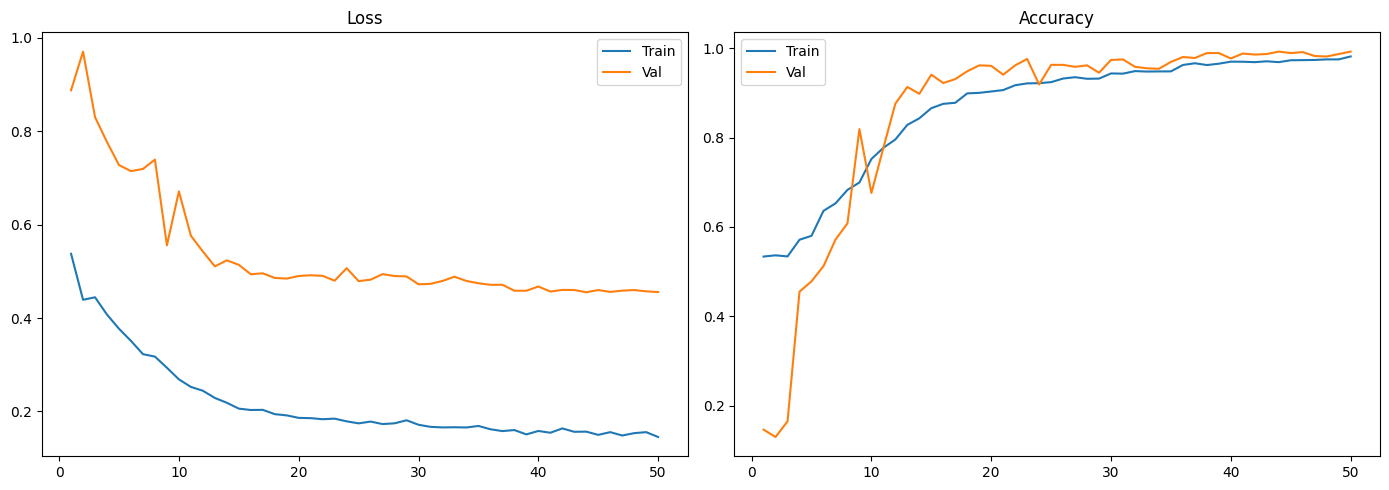

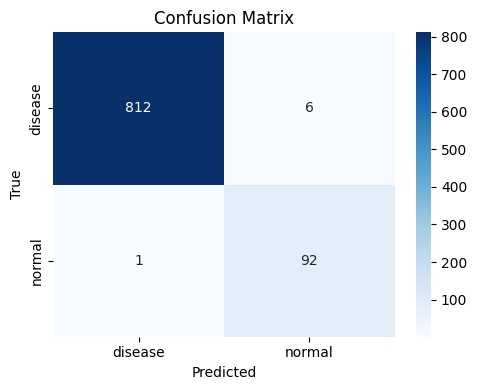

In [1]:
"""
VGG-16 From Scratch — Eye Disease Classification
Auto-detects Kaggle dataset paths at runtime.
"""

import os, math, random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.datasets.folder import default_loader
from torch.optim.lr_scheduler import ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

# ──────────────────────────────────────────────
# 0. AUTO PATH DETECTION
# ──────────────────────────────────────────────
def find_dir(name_fragments: list[str], search_roots: list[str]) -> str | None:
    """
    Walk search_roots and return the first directory whose path contains
    ALL strings in name_fragments (case-insensitive).
    """
    for root in search_roots:
        for dirpath, dirnames, _ in os.walk(root):
            dp_lower = dirpath.lower()
            if all(frag.lower() in dp_lower for frag in name_fragments):
                return dirpath
    return None

SEARCH_ROOTS = ["/kaggle/input", "/content", ".", ".."]

# ── Locate disease folder (retinitis pigmentosa dataset root)
DISEASE_DIR = find_dir(["retinitis"], SEARCH_ROOTS)

# ── Locate normal folder inside eye_diseases_classification
NORMAL_DIR  = find_dir(["eye_diseases", "normal"], SEARCH_ROOTS)

# ── Fallback: let user override manually
DISEASE_DIR = DISEASE_DIR or "dataset_retinitis_pigmentosa_enhanced/"
NORMAL_DIR  = NORMAL_DIR  or "eye_diseases_classification/eye_diseases_classification/normal/"

print("=" * 60)
print(f"[PATH] Disease dir : {DISEASE_DIR}")
print(f"[PATH] Normal  dir : {NORMAL_DIR}")
print("=" * 60)

# Sanity check
for label, path in [("Disease", DISEASE_DIR), ("Normal", NORMAL_DIR)]:
    if not os.path.isdir(path):
        raise FileNotFoundError(
            f"\n❌  {label} directory not found: '{path}'\n"
            f"    Please set DISEASE_DIR / NORMAL_DIR manually at the top of the script."
        )

CONFIG = {
    "train_ratio":         0.80,
    "val_ratio":           0.10,
    "test_ratio":          0.10,
    "image_size":          224,
    "batch_size":          32,
    "num_epochs":          50,
    "learning_rate":       1e-4,
    "weight_decay":        1e-4,
    "dropout_conv":        0.4,
    "dropout_fc":          0.5,
    "label_smoothing":     0.1,
    "grad_clip":           1.0,
    "early_stop_patience": 10,
    "num_workers":         2,        # 2 is safe for Kaggle/Colab
    "seed":                42,
    "checkpoint_path":     "best_vgg16_eye.pth",
}

CLASSES = ["disease", "normal"]
DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])
random.seed(CONFIG["seed"])
print(f"Device : {DEVICE}\n")


# ──────────────────────────────────────────────
# 1. IMAGE COLLECTION
# ──────────────────────────────────────────────
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tiff", ".tif", ".webp"}

def collect_image_paths(folder: str) -> list[str]:
    paths = []
    for root, _, files in os.walk(folder):
        for f in files:
            if os.path.splitext(f)[1].lower() in IMG_EXTS:
                paths.append(os.path.join(root, f))
    return sorted(paths)


def build_split(disease_dir: str, normal_dir: str):
    disease_paths = collect_image_paths(disease_dir)
    normal_paths  = collect_image_paths(normal_dir)

    if len(disease_paths) == 0:
        raise RuntimeError(f"No images found in disease dir: {disease_dir}")
    if len(normal_paths) == 0:
        raise RuntimeError(f"No images found in normal dir:  {normal_dir}")

    print(f"Disease images : {len(disease_paths)}")
    print(f"Normal  images : {len(normal_paths)}")

    all_samples = (
        [(p, 0) for p in disease_paths] +
        [(p, 1) for p in normal_paths]
    )
    random.shuffle(all_samples)

    n    = len(all_samples)
    n_tr = int(n * CONFIG["train_ratio"])
    n_vl = int(n * CONFIG["val_ratio"])

    train_s = all_samples[:n_tr]
    val_s   = all_samples[n_tr : n_tr + n_vl]
    test_s  = all_samples[n_tr + n_vl :]

    print(f"Train : {len(train_s)} | Val : {len(val_s)} | Test : {len(test_s)}\n")
    return train_s, val_s, test_s


# ──────────────────────────────────────────────
# 2. DATASET CLASS
# ──────────────────────────────────────────────
class EyeDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples   = samples
        self.transform = transform
        self.loader    = default_loader

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = self.loader(path)
        if self.transform:
            img = self.transform(img)
        return img, label


# ──────────────────────────────────────────────
# 3. AUGMENTATION
# ──────────────────────────────────────────────
class Cutout:
    def __init__(self, n_holes=1, length=48):
        self.n_holes = n_holes
        self.length  = length

    def __call__(self, img):
        h, w = img.shape[1], img.shape[2]
        mask = torch.ones(h, w)
        for _ in range(self.n_holes):
            cy, cx = np.random.randint(h), np.random.randint(w)
            y1 = max(0, cy - self.length // 2)
            y2 = min(h, cy + self.length // 2)
            x1 = max(0, cx - self.length // 2)
            x2 = min(w, cx + self.length // 2)
            mask[y1:y2, x1:x2] = 0.0
        return img * mask.unsqueeze(0)


SZ       = CONFIG["image_size"]
IMG_MEAN = [0.485, 0.456, 0.406]
IMG_STD  = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((SZ + 24, SZ + 24)),
    transforms.RandomCrop(SZ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.3),
    transforms.RandomRotation(degrees=25),
    transforms.ColorJitter(brightness=0.35, contrast=0.35,
                           saturation=0.25, hue=0.06),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1),
                            scale=(0.88, 1.12), shear=8),
    transforms.RandomGrayscale(p=0.05),
    transforms.ToTensor(),
    transforms.Normalize(IMG_MEAN, IMG_STD),
    Cutout(n_holes=1, length=48),
])

eval_tf = transforms.Compose([
    transforms.Resize((SZ, SZ)),
    transforms.ToTensor(),
    transforms.Normalize(IMG_MEAN, IMG_STD),
])


# ──────────────────────────────────────────────
# 4. DATALOADERS
# ──────────────────────────────────────────────
def build_loaders():
    train_s, val_s, test_s = build_split(DISEASE_DIR, NORMAL_DIR)

    train_ds = EyeDataset(train_s, train_tf)
    val_ds   = EyeDataset(val_s,   eval_tf)
    test_ds  = EyeDataset(test_s,  eval_tf)

    # WeightedRandomSampler — oversamples minority (normal) class
    labels       = [lbl for _, lbl in train_s]
    counts       = np.bincount(labels)             # [n_disease, n_normal]
    cls_w        = 1.0 / counts.astype(float)
    samp_w       = torch.tensor([cls_w[l] for l in labels], dtype=torch.double)
    sampler      = WeightedRandomSampler(samp_w, num_samples=int(len(samp_w)),
                                         replacement=True)

    nw = CONFIG["num_workers"]
    train_loader = DataLoader(train_ds, batch_size=CONFIG["batch_size"],
                              sampler=sampler, num_workers=nw, pin_memory=True)
    val_loader   = DataLoader(val_ds,   batch_size=CONFIG["batch_size"],
                              shuffle=False, num_workers=nw, pin_memory=True)
    test_loader  = DataLoader(test_ds,  batch_size=CONFIG["batch_size"],
                              shuffle=False, num_workers=nw, pin_memory=True)

    # Loss weights (disease=0 gets lower weight since it dominates)
    loss_w = torch.tensor(cls_w / cls_w.sum() * 2, dtype=torch.float32).to(DEVICE)
    print(f"Loss weights → disease:{loss_w[0]:.4f}  normal:{loss_w[1]:.4f}\n")
    return train_loader, val_loader, test_loader, loss_w


# ──────────────────────────────────────────────
# 5. VGG-16 MODEL
# ──────────────────────────────────────────────
class ConvBN(nn.Module):
    def __init__(self, in_c, out_c, dropout=0.0):
        super().__init__()
        layers = [
            nn.Conv2d(in_c, out_c, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
        ]
        if dropout > 0:
            layers.append(nn.Dropout2d(p=dropout))
        self.block = nn.Sequential(*layers)

    def forward(self, x): return self.block(x)


class VGG16(nn.Module):
    def __init__(self, num_classes=2, dc=0.4, df=0.5):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1  224→112
            ConvBN(  3,  64), ConvBN( 64,  64),
            nn.MaxPool2d(2, 2),
            # Block 2  112→56
            ConvBN( 64, 128), ConvBN(128, 128),
            nn.MaxPool2d(2, 2),
            # Block 3  56→28
            ConvBN(128, 256), ConvBN(256, 256), ConvBN(256, 256, dc),
            nn.MaxPool2d(2, 2),
            # Block 4  28→14
            ConvBN(256, 512), ConvBN(512, 512), ConvBN(512, 512, dc),
            nn.MaxPool2d(2, 2),
            # Block 5  14→7
            ConvBN(512, 512), ConvBN(512, 512), ConvBN(512, 512, dc),
            nn.MaxPool2d(2, 2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512 * 7 * 7, 2048), nn.BatchNorm1d(2048),
            nn.ReLU(inplace=True), nn.Dropout(df),
            nn.Linear(2048, 2048), nn.BatchNorm1d(2048),
            nn.ReLU(inplace=True), nn.Dropout(df),
            nn.Linear(2048, num_classes),
        )
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, (nn.BatchNorm2d, nn.BatchNorm1d)):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.classifier(self.features(x))


# ──────────────────────────────────────────────
# 6. TRAIN / EVAL
# ──────────────────────────────────────────────
def train_epoch(model, loader, criterion, optimizer):
    model.train()
    loss_sum = correct = total = 0
    for imgs, labels in tqdm(loader, desc="  Train", leave=False):
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        out  = model(imgs)
        loss = criterion(out, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), CONFIG["grad_clip"])
        optimizer.step()
        loss_sum += loss.item() * imgs.size(0)
        correct  += (out.argmax(1) == labels).sum().item()
        total    += imgs.size(0)
    return loss_sum / total, correct / total


@torch.no_grad()
def eval_epoch(model, loader, criterion):
    model.eval()
    loss_sum = correct = total = 0
    all_p, all_l = [], []
    for imgs, labels in tqdm(loader, desc="  Eval ", leave=False):
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        out  = model(imgs)
        loss = criterion(out, labels)
        loss_sum += loss.item() * imgs.size(0)
        pred      = out.argmax(1)
        correct  += (pred == labels).sum().item()
        total    += imgs.size(0)
        all_p.extend(pred.cpu().tolist())
        all_l.extend(labels.cpu().tolist())
    return loss_sum / total, correct / total, all_p, all_l


# ──────────────────────────────────────────────
# 7. PLOTS
# ──────────────────────────────────────────────
def plot_history(h):
    ep = range(1, len(h["tl"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].plot(ep, h["tl"], label="Train"); ax[0].plot(ep, h["vl"], label="Val")
    ax[0].set_title("Loss"); ax[0].legend()
    ax[1].plot(ep, h["ta"], label="Train"); ax[1].plot(ep, h["va"], label="Val")
    ax[1].set_title("Accuracy"); ax[1].legend()
    plt.tight_layout(); plt.savefig("training_history.png", dpi=150); plt.show()

def plot_cm(labels, preds):
    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASSES, yticklabels=CLASSES)
    plt.title("Confusion Matrix"); plt.ylabel("True"); plt.xlabel("Predicted")
    plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=150); plt.show()


# ──────────────────────────────────────────────
# 8. MAIN
# ──────────────────────────────────────────────
def main():
    train_loader, val_loader, test_loader, loss_w = build_loaders()

    model = VGG16(num_classes=2,
                  dc=CONFIG["dropout_conv"],
                  df=CONFIG["dropout_fc"]).to(DEVICE)
    print(f"Params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}\n")

    criterion = nn.CrossEntropyLoss(weight=loss_w,
                                    label_smoothing=CONFIG["label_smoothing"])
    optimizer = optim.AdamW(model.parameters(),
                            lr=CONFIG["learning_rate"],
                            weight_decay=CONFIG["weight_decay"])
    scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=0.5,
                                  patience=4, min_lr=1e-7)

    h = {"tl": [], "vl": [], "ta": [], "va": []}
    best_loss  = math.inf
    no_improve = 0

    for epoch in range(1, CONFIG["num_epochs"] + 1):
        tl, ta = train_epoch(model, train_loader, criterion, optimizer)
        vl, va, _, _ = eval_epoch(model, val_loader, criterion)
        scheduler.step(vl)

        h["tl"].append(tl); h["vl"].append(vl)
        h["ta"].append(ta); h["va"].append(va)

        flag = "⚠ overfit?" if (ta - va) > 0.10 else "✓"
        print(f"Ep {epoch:03d} | Train L:{tl:.4f} A:{ta:.4f} | "
              f"Val L:{vl:.4f} A:{va:.4f} | Gap:{ta-va:+.4f} {flag}")

        if vl < best_loss:
            best_loss  = vl
            no_improve = 0
            torch.save({"epoch": epoch, "model_state": model.state_dict(),
                        "val_loss": vl, "val_acc": va}, CONFIG["checkpoint_path"])
            print(f"         └─ ✓ Saved (val_loss={vl:.4f})")
        else:
            no_improve += 1
            if no_improve >= CONFIG["early_stop_patience"]:
                print(f"\nEarly stopping at epoch {epoch}.")
                break

    ckpt = torch.load(CONFIG["checkpoint_path"], map_location=DEVICE)
    model.load_state_dict(ckpt["model_state"])
    print(f"\nBest epoch: {ckpt['epoch']}  val_acc: {ckpt['val_acc']:.4f}")

    te_loss, te_acc, te_p, te_l = eval_epoch(model, test_loader, criterion)
    print(f"\nTest Loss:{te_loss:.4f}  Acc:{te_acc:.4f}\n")
    print(classification_report(te_l, te_p, target_names=CLASSES))

    # Save variables globally
    globals()['h'] = h
    globals()['te_l'] = te_l
    globals()['te_p'] = te_p

    # Plot graphs
    plot_history(h)
    plot_cm(te_l, te_p)


if __name__ == "__main__":
    main()